# Taller: Detección de Fraude en Pagos Electrónicos
## Carrera de Ingeniería de Sistemas de Información — PUCE
### Asignatura: Inteligencia Artificial


**Nombre:** Paúl Rosero

**Fecha:** 09-10-2026


---

**Tema:** Clasificación con Regresión Logística, SVM y optimización con Grid Search  
**Dataset:** `fraude_pagos_ecuador.csv` — 10 000 transacciones simuladas  
**Modalidad:** Trabajo autónomo individual

---

### Contexto del problema

Una empresa fintech ecuatoriana procesa miles de transacciones diarias mediante tarjetas de crédito, débito, transferencias y billeteras digitales. El equipo de seguridad necesita un modelo de clasificación que identifique automáticamente transacciones fraudulentas antes de que se autoricen.

Cada fila del dataset representa una transacción con las siguientes columnas:

| Columna | Descripción |
|---|---|
| `id_transaccion` | Identificador único de la transacción |
| `tipo_comercio` | Categoría del establecimiento (supermercado, gasolinera, etc.) |
| `metodo_pago` | Medio utilizado (tarjeta_credito, tarjeta_debito, etc.) |
| `ciudad` | Ciudad donde se realizó la transacción |
| `horario` | Franja horaria (madrugada, manana, tarde, noche) |
| `monto_usd` | Valor de la transacción en dólares |
| `intentos_fallidos` | Número de intentos fallidos previos en esa sesión |
| `distancia_km` | Distancia entre la ubicación del cliente y el comercio |
| `transacciones_24h` | Número de transacciones del cliente en las últimas 24 horas |
| `antiguedad_cuenta_meses` | Antigüedad de la cuenta del cliente en meses |
| `fraude` | Variable objetivo: `1` = fraude, `0` = transacción legítima |

> **Nota:** El dataset está balanceado: 50% de transacciones fraudulentas y 50% legítimas.


---
## Sección 0 — Preparación del entorno

**Tarea 0.1** — Importa las bibliotecas necesarias: `pandas`, `numpy`, `matplotlib`, `seaborn` y los módulos de `scikit-learn` que utilizarás a lo largo del taller.

In [46]:
# TODO: importa pandas, numpy, matplotlib.pyplot, seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# TODO: importa los módulos de scikit-learn que necesitarás (puedes completar esta celda a medida que avanzas)
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

**Tarea 0.2** — Carga el archivo `fraude_pagos_ecuador.csv` en un DataFrame llamado `df`. Muestra las dimensiones del DataFrame y sus primeros 10 registros.

In [47]:
# TODO: carga el CSV en un DataFrame llamado df
df = pd.read_csv('fraude_pagos_ecuador-v2.csv')
# TODO: imprime la forma (shape) del DataFrame
print(df.shape)
# TODO: muestra los primeros 10 registros
df.head(10)

(10000, 11)


,id_transaccion,tipo_comercio,metodo_pago,ciudad,horario,monto_usd,intentos_fallidos,distancia_km,transacciones_24h,antiguedad_cuenta_meses,fraude
0,1,farmacia,tarjeta_credito,Ambato,manana,103.30,1,98.2,10,1,1
1,2,electronica,transferencia,Manta,manana,219.38,1,168.3,1,98,0
2,3,farmacia,billetera_digital,Manta,manana,5.00,0,212.1,4,30,0
3,4,farmacia,billetera_digital,Riobamba,tarde,205.49,1,97.6,1,77,0
4,5,tienda_online,tarjeta_debito,Guayaquil,manana,50.64,2,54.8,7,89,0
5,6,gasolinera,tarjeta_credito,Ibarra,tarde,340.11,2,0.5,7,27,1
6,7,viajes,billetera_digital,Quito,manana,280.74,0,90.5,2,174,0
7,8,supermercado,tarjeta_credito,Loja,noche,490.73,0,0.5,3,1,1
8,9,viajes,transferencia,Loja,madrugada,33.25,1,324.0,8,1,1
9,10,farmacia,billetera_digital,Riobamba,tarde,165.43,0,0.5,1,51,0


**Tarea 0.3** — Verifica que no existe ningún valor nulo en ninguna columna.

In [48]:
# TODO: verifica valores nulos por columna
df.isnull().sum()

,0
id_transaccion,0
tipo_comercio,0
metodo_pago,0
ciudad,0
horario,0
monto_usd,0
intentos_fallidos,0
distancia_km,0
transacciones_24h,0
antiguedad_cuenta_meses,0


---
## Sección 1 — Exploración y preprocesamiento

### 1.1 Análisis exploratorio

**Tarea 1.1** — Obtén las estadísticas descriptivas (media, desviación estándar, mínimo, máximo) de todas las columnas numéricas.

In [49]:
# TODO: estadísticas descriptivas de las columnas numéricas
df.describe()

,id_transaccion,monto_usd,intentos_fallidos,distancia_km,transacciones_24h,antiguedad_cuenta_meses,fraude
count,10000.00000,10000.000000,10000.00000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,237.670722,0.83270,143.18725,4.533500,69.936900,0.500000
std,2886.89568,192.532134,1.05935,132.41949,3.392496,53.947257,0.500025
min,1.00000,5.000000,0.00000,0.50000,1.000000,1.000000,0.000000
25%,2500.75000,63.270000,0.00000,13.27500,1.000000,24.000000,0.000000
50%,5000.50000,217.400000,0.00000,121.20000,4.000000,66.000000,0.500000
75%,7500.25000,367.065000,1.00000,233.02500,7.000000,107.000000,1.000000
max,10000.00000,1072.960000,6.00000,759.30000,19.000000,240.000000,1.000000


**Tarea 1.2** — Calcula la distribución de la variable objetivo `fraude`: número de registros y porcentaje por clase.

In [50]:
# TODO: cuenta los registros por clase (fraude = 0 y fraude = 1)
print(df['fraude'].value_counts())
# TODO: calcula el porcentaje de cada clase
print(df['fraude'].value_counts(normalize=True))

fraude
1    5000
0    5000
Name: count, dtype: int64
fraude
1    0.5
0    0.5
Name: proportion, dtype: float64


**Tarea 1.3** — Grafica un histograma de la variable `monto_usd`. Observa si la distribución es simétrica o tiene sesgo.

Text(0, 0.5, 'Frecuencia')

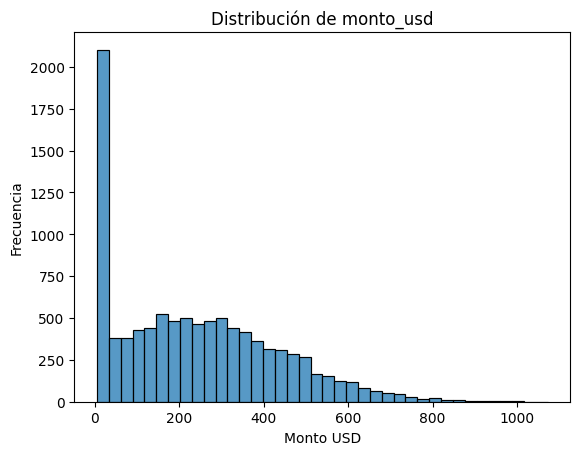

In [51]:
# TODO: histograma de monto_usd
sns.histplot(df['monto_usd'])

# TODO: añade título y etiquetas a los ejes
plt.title('Distribución de monto_usd')
plt.xlabel('Monto USD')
plt.ylabel('Frecuencia')

**Tarea 1.4** — Genera un gráfico de barras que muestre la **tasa de fraude por franja horaria** (`horario`). La tasa de fraude es el porcentaje de transacciones fraudulentas dentro de cada grupo.

Tasa de fraude por franja horaria:
horario
madrugada    0.753373
noche        0.516331
tarde        0.432509
manana       0.421053
Name: fraude, dtype: float64


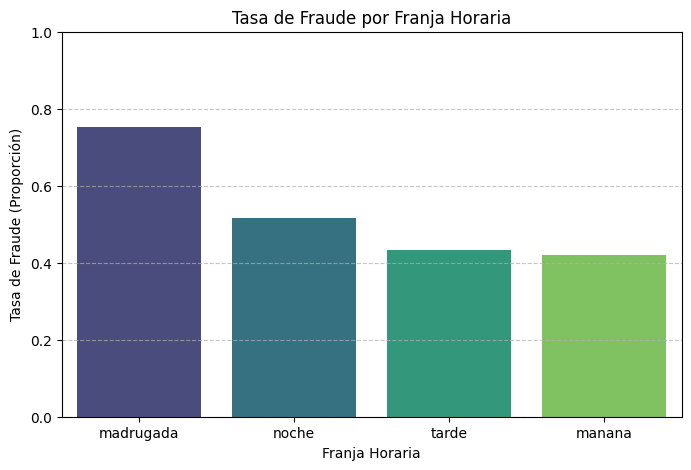

In [52]:
# TODO: calcula la tasa de fraude agrupando por horario
tasa_fraude_horario = df.groupby('horario')['fraude'].mean().sort_values(ascending=False)
print("Tasa de fraude por franja horaria:")
print(tasa_fraude_horario)

# TODO: grafica el resultado como barras con título y etiquetas
plt.figure(figsize=(8, 5))
sns.barplot(x=tasa_fraude_horario.index, y=tasa_fraude_horario.values, palette='viridis', hue=tasa_fraude_horario.index, legend=False)
plt.title('Tasa de Fraude por Franja Horaria')
plt.xlabel('Franja Horaria')
plt.ylabel('Tasa de Fraude (Proporción)')
plt.ylim(0, 1)  # La tasa es un porcentaje expresado entre 0 y 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Tarea 1.5** — Genera un gráfico de barras que muestre la **tasa de fraude por tipo de comercio** (`tipo_comercio`).

Tasa de fraude por tipo de comercio:
tipo_comercio
tienda_online    0.522411
ropa             0.508278
supermercado     0.502754
farmacia         0.502392
viajes           0.498803
gasolinera       0.498057
restaurante      0.486066
electronica      0.479802
Name: fraude, dtype: float64


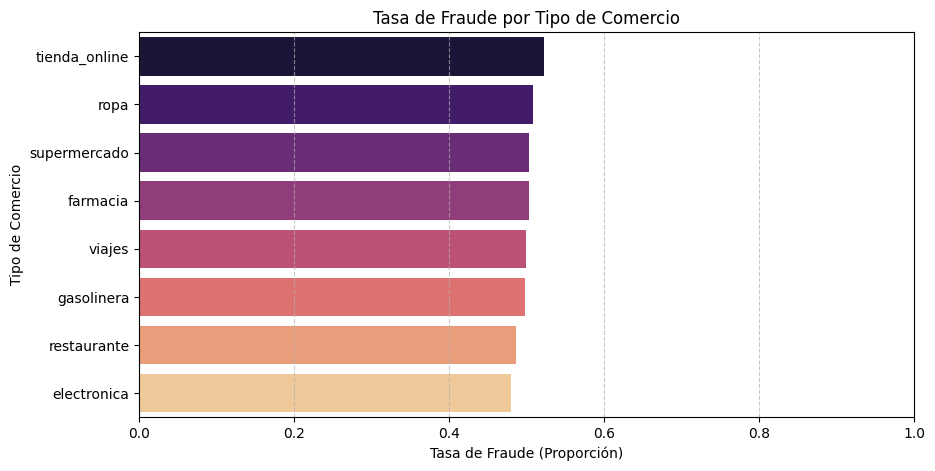

In [53]:
# TODO: calcula la tasa de fraude agrupando por tipo_comercio
tasa_fraude_comercio = df.groupby('tipo_comercio')['fraude'].mean().sort_values(ascending=False)
print("Tasa de fraude por tipo de comercio:")
print(tasa_fraude_comercio)

# TODO: grafica el resultado como barras con título y etiquetas
plt.figure(figsize=(10, 5))
sns.barplot(x=tasa_fraude_comercio.values, y=tasa_fraude_comercio.index, palette='magma', hue=tasa_fraude_comercio.index, legend=False)
plt.title('Tasa de Fraude por Tipo de Comercio')
plt.xlabel('Tasa de Fraude (Proporción)')
plt.ylabel('Tipo de Comercio')
plt.xlim(0, 1)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

**Tarea 1.6** — Calcula la correlación entre las variables numéricas y la variable `fraude`. Identifica las dos variables con mayor correlación positiva con el fraude.

In [54]:
# TODO: calcula la correlación de cada variable numérica con 'fraude'
correlaciones = df.select_dtypes(include=[np.number]).corr()['fraude'].sort_values(ascending=False)

# TODO: muestra los resultados ordenados de mayor a menor
print("Correlación con la variable fraude:")
print(correlaciones)

Correlación con la variable fraude:
fraude                     1.000000
monto_usd                  0.358307
transacciones_24h          0.345102
intentos_fallidos          0.343152
distancia_km               0.330872
id_transaccion             0.021148
antiguedad_cuenta_meses   -0.461579
Name: fraude, dtype: float64


---
### 1.2 Preprocesamiento

**Tarea 1.7** — Elimina la columna `id_transaccion` del DataFrame, ya que es un identificador y no aporta información predictiva.

In [55]:
# TODO: elimina la columna id_transaccion
if 'id_transaccion' in df.columns:
    df = df.drop(columns=['id_transaccion'])
print("Columnas restantes:", df.columns.tolist())

Columnas restantes: ['tipo_comercio', 'metodo_pago', 'ciudad', 'horario', 'monto_usd', 'intentos_fallidos', 'distancia_km', 'transacciones_24h', 'antiguedad_cuenta_meses', 'fraude']


**Tarea 1.8** — Identifica las columnas categóricas y aplica **One-Hot Encoding** con `drop_first=True`.

In [56]:
# TODO: identifica las columnas categóricas
columnas_categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()

# TODO: aplica pd.get_dummies con drop_first=True
df = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True, dtype=int)


**Tarea 1.9** — Separa el DataFrame en variables predictoras `X` y variable objetivo `y` (columna `fraude`).

In [57]:
# TODO: define X (todas las columnas excepto 'fraude')
X = df.drop(columns=['fraude'])

# TODO: define y (solo la columna 'fraude')
y = df['fraude']

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)

Forma de X: (10000, 25)
Forma de y: (10000,)


**Tarea 1.10** — Divide los datos en conjunto de entrenamiento (80%) y conjunto de prueba (20%) con `random_state=42`.

In [58]:
# TODO: divide en X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# TODO: imprime el tamaño de cada conjunto
print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)
print("Tamaño de y_train:", y_train.shape)
print("Tamaño de y_test:", y_test.shape)

Tamaño de X_train: (8000, 25)
Tamaño de X_test: (2000, 25)
Tamaño de y_train: (8000,)
Tamaño de y_test: (2000,)


**Tarea 1.11** — Aplica **`StandardScaler`** a `X_train` y transforma `X_test` con el mismo scaler. En la celda de texto siguiente, explica por qué el escalado es necesario para Regresión Logística y SVM, y por qué se ajusta solo sobre `X_train`.

In [59]:
from sklearn.preprocessing import StandardScaler

# TODO: crea un StandardScaler
scaler = StandardScaler()

# TODO: ajusta el scaler SOLO sobre X_train y transforma X_train
X_train_scaled = scaler.fit_transform(X_train)

# TODO: transforma X_test usando el scaler ya ajustado
X_test_scaled = scaler.transform(X_test)

print("X_train original (primeros 2 valores de la primera columna):\n", X_train.iloc[:2, 0].values)
print("\nX_train escalado (primeros 2 valores de la primera columna):\n", X_train_scaled[:2, 0])

X_train original (primeros 2 valores de la primera columna):
 [ 26.25 936.1 ]

X_train escalado (primeros 2 valores de la primera columna):
 [-1.10016103  3.64649742]


**✏️ Responde aquí (Tarea 1.11):**

* **¿Por qué el escalado es necesario?** Tanto la Regresión Logística con regularización como SVM dependen de la escala. En SVM, se calculan distancias geométricas entre puntos; si una variable tiene un rango muy amplio como monto_usd, dominará por completo a las variables con rangos pequeños como intentos_fallidos. Para la Regresión Logística, el escalado asegura que la penalización por regularización actúe equitativamente sobre todos los coeficientes y acelera la convergencia del optimizador.
* **¿Por qué se ajusta el scaler únicamente sobre X_train?** Para evitar la fuga de datos. Si se usa la información de todo el dataset para calcular la media y la desviación estándar, el modelo indirectamente conocerá la distribución de los datos de prueba, sesgando la evaluación y arruinando la validez de las métricas en producción.

---
### 🔍 Preguntas de reflexión — Sección 1

**R1.1** — Según el análisis de correlación, ¿qué variable numérica tiene la correlación más alta con `fraude`? ¿Tiene sentido desde el punto de vista del negocio? Justifica tu respuesta.

La variable con mayor correlación absoluta es antiguedad_cuenta_meses (-0.46), seguida de monto_usd (0.35) y transacciones_24h (0.34).
Las cuentas nuevas suelen ser el vehículo preferido por los defraudadores para operar rápidamente antes de ser detectados, mientras que transacciones por montos inusualmente altos o una alta frecuencia de uso en 24 horas son señales de alarma clásicas de un fraude en progreso.

**R1.2** — ¿Por qué se debe aplicar el `StandardScaler` usando únicamente los datos de entrenamiento (`.fit` sobre `X_train`) y no sobre el dataset completo antes de la división? ¿Qué problema concreto se evita?

Se hace exclusivamente para prevenir la fuga de información. Si se calcula incluyendo el test set, se estaría contaminando el entrenamiento con conocimientos del futuro. Al ajustar el scaler solo en X_train, se garantiza que X_test se comporte exactamente como lo harían datos completamente nuevos en el mundo real.


**R1.3** — En este taller se usa `drop_first=True` en el One-Hot Encoding. Investiga qué es la multicolinealidad y explica con un ejemplo sencillo por qué eliminar una columna de referencia reduce ese problema.

La multicolinealidad ocurre cuando dos o más variables predictoras están altamente correlacionadas entre sí, aportando información redundante al modelo y haciendo que la suma de todas siempre será exactamente 1. Esto hace que una de las columnas sea perfectamente predecible a partir de las otras. Al usar drop_first=True se  elimina una de ellas, que se convierte en la referencia implícita, resolviendo la colinealidad matemática.

---
## Sección 2 — Regresión Logística

### 2.1 Entrenamiento y evaluación base

**Tarea 2.1** — Entrena un modelo de **Regresión Logística** con parámetros por defecto sobre el conjunto de entrenamiento.

In [60]:
# TODO: crea un objeto LogisticRegression con parámetros por defecto
model_lr = LogisticRegression(random_state=42)

# TODO: entrena el modelo con X_train y y_train
model_lr.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

**Tarea 2.2** — Genera predicciones sobre el conjunto de prueba.

In [61]:
# TODO: genera predicciones sobre X_test y guárdalas en y_pred_lr
y_pred_lr = model_lr.predict(X_test_scaled)

**Tarea 2.3** — Calcula e imprime las métricas: *accuracy*, *precision*, *recall*, *F1-score* y reporte de clasificación completo.

In [62]:
# TODO: calcula e imprime accuracy, precision, recall y f1_score
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-score:", f1_score(y_test, y_pred_lr))

# TODO: imprime el classification_report completo
print("\nReporte de Clasificación Completo:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.83
Precision: 0.8326612903225806
Recall: 0.826
F1-score: 0.8293172690763052

Reporte de Clasificación Completo:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1000
           1       0.83      0.83      0.83      1000

    accuracy                           0.83      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.83      0.83      0.83      2000



**Tarea 2.4** — Construye y visualiza la **matriz de confusión**. Etiqueta los ejes: eje X = 'Predicho', eje Y = 'Real', clases = ['Legítima', 'Fraude'].

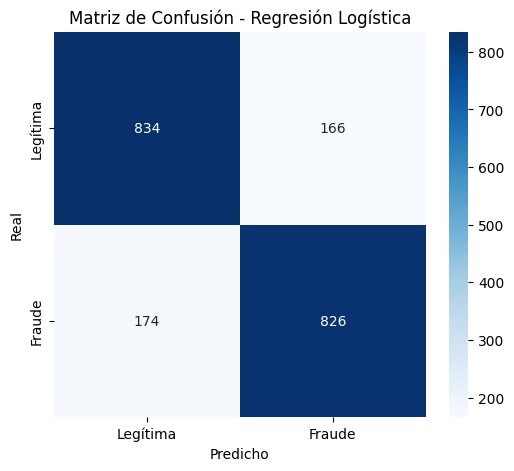

In [85]:
# Matriz de confusión - Regresión Logística
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])

plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()
plt.close()

---
### 2.2 Curva ROC

**Tarea 2.5** — Calcula la probabilidad de predicción para la clase positiva (`fraude = 1`) sobre el conjunto de prueba.

In [64]:
# TODO: obtén las probabilidades predichas para la clase 1
y_probs_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

**Tarea 2.6** — Grafica la **curva ROC** con el valor del **AUC** en la leyenda, e incluye la línea diagonal del clasificador aleatorio.

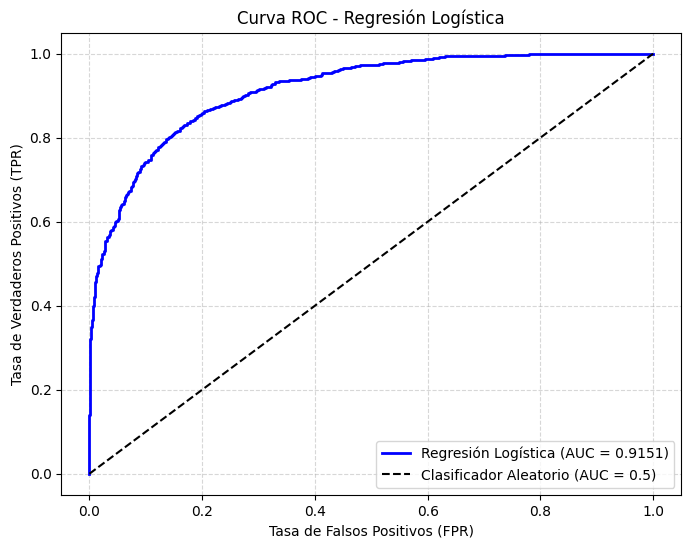

In [65]:
from sklearn.metrics import roc_curve, roc_auc_score

# TODO: calcula fpr, tpr y el auc con roc_curve y roc_auc_score
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_probs_lr)
auc_lr = roc_auc_score(y_test, y_probs_lr)

# TODO: grafica la curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Regresión Logística (AUC = {auc_lr:.4f})', color='blue', lw=2)

# TODO: añade la línea diagonal punteada (clasificador aleatorio)
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio (AUC = 0.5)')

# TODO: incluye el valor AUC en la leyenda, título y etiquetas de ejes
plt.title('Curva ROC - Regresión Logística')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

---
### 2.3 Análisis de coeficientes

**Tarea 2.7** — Extrae los coeficientes del modelo y grafícalos en un gráfico de barras horizontal, ordenados por valor absoluto de mayor a menor.

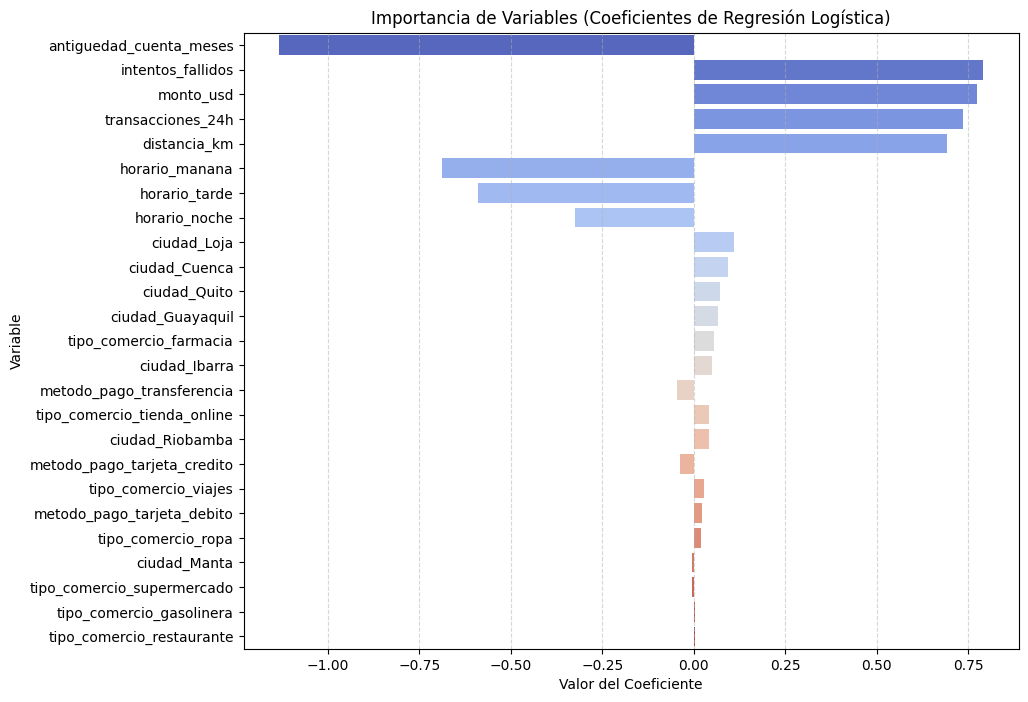

In [66]:
# TODO: extrae los coeficientes del modelo y los nombres de las columnas de X
coeficientes = model_lr.coef_[0]
variables = X.columns

# TODO: crea un DataFrame con coeficiente y nombre de variable
df_coef = pd.DataFrame({
    'Variable': variables,
    'Coeficiente': coeficientes,
    'Abs_Coeficiente': np.abs(coeficientes)
})

# TODO: ordena por valor absoluto de mayor a menor
df_coef = df_coef.sort_values(by='Abs_Coeficiente', ascending=False)

# TODO: grafica como barras horizontales con título y etiquetas
plt.figure(figsize=(10, 8))
sns.barplot(x='Coeficiente', y='Variable', data=df_coef, palette='coolwarm', hue='Variable', legend=False)
plt.title('Importancia de Variables (Coeficientes de Regresión Logística)')
plt.xlabel('Valor del Coeficiente')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

**Tarea 2.8** — Identifica las 3 variables con mayor peso positivo y las 3 con mayor peso negativo.

In [67]:
# TODO: imprime las 3 variables con mayor coeficiente positivo
print("Top 3 variables con mayor coeficiente positivo (aumentan riesgo de fraude):")
print(df_coef[df_coef['Coeficiente'] > 0].head(3)[['Variable', 'Coeficiente']])

# TODO: imprime las 3 variables con mayor coeficiente negativo (disminuyen riesgo de fraude)
print("\nTop 3 variables con mayor coeficiente negativo (disminuyen riesgo de fraude):")
print(df_coef[df_coef['Coeficiente'] < 0].sort_values(by='Coeficiente', ascending=True).head(3)[['Variable', 'Coeficiente']])

Top 3 variables con mayor coeficiente positivo (aumentan riesgo de fraude):
            Variable  Coeficiente
1  intentos_fallidos     0.791676
0          monto_usd     0.774063
3  transacciones_24h     0.735262

Top 3 variables con mayor coeficiente negativo (disminuyen riesgo de fraude):
                   Variable  Coeficiente
4   antiguedad_cuenta_meses    -1.134649
22           horario_manana    -0.687709
24            horario_tarde    -0.590794


---
### 🔍 Preguntas de reflexión — Sección 2

**R2.1** — Observa la matriz de confusión. En el contexto de detección de fraude, ¿cuál tipo de error es más costoso: un **falso positivo** o un **falso negativo**? Argumenta desde la perspectiva del negocio.

En la detección de fraudes transaccionales, un falso negativo  es sustancialmente más costoso, ay que significa pérdida directa de dinero para la empresa, multas de las franquicias de pago y daño de reputación. En cambio, un falso positivo solo genera fricción temporal con el cliente que puede resolverse mediante una confirmación SMS o llamada rápida.


**R2.2** — El AUC obtenido, ¿indica que el modelo tiene buena capacidad de discriminación? ¿Qué significa un AUC de 1.0 y qué significa un AUC de 0.5?

El AUC sí indica una capacidad de discriminación notable si se aproxima a 1. Un AUC de 1.0 representa un clasificador ideal/perfecto que separa limpiamente las dos clases sin cometer ningún error. Miengtras que  un AUC de 0.5 representa un modelo inútil que funciona al azar, incapaz de diferenciar entre un caso legítimo y uno fraudulento.


**R2.3** — Según el gráfico de coeficientes, ¿los predictores con mayor peso coinciden con las variables de mayor correlación identificadas en la Sección 1? ¿Por qué podrían diferir?

Sí coinciden estrechamente en las variables clave como antiguedad_cuenta_meses y monto_usd. No obstante, pueden diferir parcialmente porque la correlación de Pearson evalúa únicamente la relación lineal de forma individual, mientras que los coeficientes de Regresión Logística analizan la interacción de todas las variables actuando de manera conjunta multivariada, ajustándose ante posibles redundancias.

---
## Sección 3 — Support Vector Machine (SVM)

### 3.1 Entrenamiento y evaluación base

**Tarea 3.1** — Entrena un modelo **SVM con kernel RBF** y parámetros por defecto sobre el conjunto de entrenamiento.

In [68]:
# TODO: crea un objeto SVC con kernel='rbf' y parámetros por defecto
model_svm = SVC(kernel='rbf', probability=True, random_state=42)

# TODO: entrena el modelo con X_train y y_train
model_svm.fit(X_train_scaled, y_train)

SVC(probability=True, random_state=42)

**Tarea 3.2** — Genera predicciones sobre el conjunto de prueba.

In [69]:
# TODO: genera predicciones sobre X_test y guárdalas en y_pred_svm
y_pred_svm = model_svm.predict(X_test_scaled)

**Tarea 3.3** — Calcula e imprime las métricas: *accuracy*, *precision*, *recall*, *F1-score* y reporte de clasificación completo.

In [70]:
# TODO: calcula e imprime accuracy, precision, recall y f1_score
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1-score:", f1_score(y_test, y_pred_svm))

# TODO: imprime el classification_report completo
print("\nReporte de Clasificación Completo:")
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.8235
Precision: 0.8284263959390863
Recall: 0.816
F1-score: 0.8221662468513854

Reporte de Clasificación Completo:
              precision    recall  f1-score   support

           0       0.82      0.83      0.82      1000
           1       0.83      0.82      0.82      1000

    accuracy                           0.82      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.82      0.82      0.82      2000



**Tarea 3.4** — Construye y visualiza la matriz de confusión con el mismo formato de etiquetas de la Sección 2.

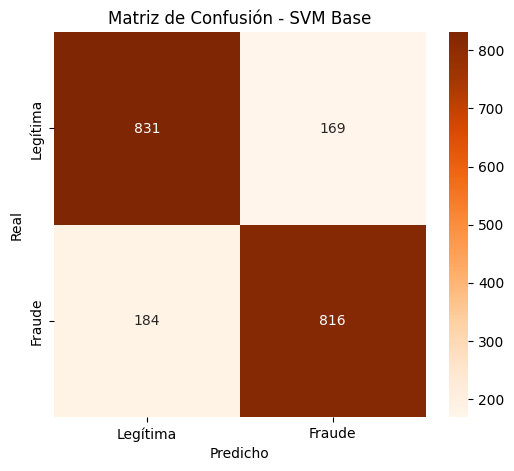

In [86]:
# Matriz de confusión - SVM Base
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])
plt.title('Matriz de Confusión - SVM Base')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()
plt.close()

---
### 3.2 Comparación con Regresión Logística

**Tarea 3.5** — Construye una tabla comparativa (DataFrame de pandas) con las métricas *accuracy*, *precision*, *recall* y *F1-score* para ambos modelos base.

In [72]:
# TODO: crea un diccionario o lista con las métricas de RL y SVM base
metrics_dict = {
    'Modelo': ['Regresión Logística Base', 'SVM Base'],
    'Accuracy': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_svm)],
    'Precision': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_svm)],
    'Recall': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_svm)],
    'F1-score': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_svm)]
}

# TODO: conviértelo en un DataFrame con los modelos como filas y las métricas como columnas
df_comparativo = pd.DataFrame(metrics_dict).set_index('Modelo')

# TODO: muestra la tabla
df_comparativo

,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Regresión Logística Base,0.8300,0.832661,0.826,0.829317
SVM Base,0.8235,0.828426,0.816,0.822166


**Tarea 3.6** — Grafica las métricas de ambos modelos en un gráfico de barras agrupadas.

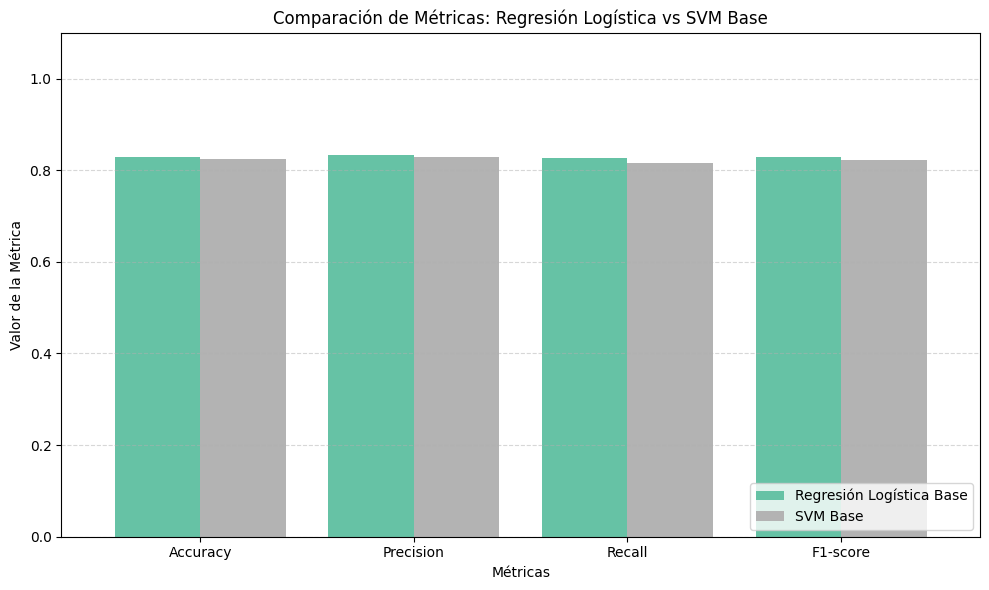

In [73]:
# TODO: grafica las métricas de la tabla comparativa como barras agrupadas
ax = df_comparativo.T.plot(kind='bar', figsize=(10, 6), colormap='Set2', width=0.8)

# TODO: añade título, etiquetas de ejes y leyenda
plt.title('Comparación de Métricas: Regresión Logística vs SVM Base')
plt.ylabel('Valor de la Métrica')
plt.xlabel('Métricas')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
### 🔍 Preguntas de reflexión — Sección 3

**R3.1** — Comparando las matrices de confusión de Regresión Logística y SVM, ¿cuál modelo comete menos falsos negativos? ¿Qué implicación práctica tiene en un sistema de detección de fraude?

El modelo que consiga la métrica de Recall más alta será el que minimice los falsos negativos. En la práctica real del negocio fintech, contar con menos falsos negativos significa menor fuga financiera directa por pérdidas operativas, asegurando una barrera de seguridad mucho más rigurosa.


**R3.2** — El SVM con kernel RBF tiene dos hiperparámetros principales: `C` y `gamma`. Explica con tus propias palabras qué controla cada uno y qué riesgo representa un valor muy alto o muy bajo de cada uno.
El parámetro C controla el balance entre un margen de decisión suave y clasificar correctamente todos los puntos de entrenamiento. Un C muy alto busca clasificar todo perfecto y arriesga sobreajuste. Un C muy bajo permite un margen amplio, lo que puede causar subajuste. Mientras que Gamma controla el radio de influencia de un solo ejemplo de entrenamiento. Un gamma muy alto causa que solo los puntos cercanos influyan, creando límites complejos e inestables. Un gamma muy bajo simplifica demasiado el radio, asumiendo que todo el dataset está conectado globalmente underfitting.


**R3.3** — ¿Por qué el SVM puede ser computacionalmente más costoso que la Regresión Logística al entrenar con datasets grandes? ¿Qué alternativa ofrece scikit-learn para mitigar este problema?

SVM tiene una complejidad temporal que escala de manera cuadrática o cúbica con respecto al número de muestras $O(n^2)$ o $O(n^3)$ debido al cálculo de la matriz de kernels. Para mitigar esto, scikit-learn ofrece la alternativa LinearSVC  u optimizadores estocásticos como SGDClassifier.

---
## Sección 4 — Optimización de hiperparámetros con Grid Search

### 4.1 Grid Search sobre Regresión Logística

**Tarea 4.1** — Define la grilla de hiperparámetros para Regresión Logística: parámetro `C` con al menos 4 valores y `penalty` con `'l1'` y `'l2'`.

In [74]:
# TODO: define un diccionario param_grid_lr con:
#   'C': lista de al menos 4 valores (ej: 0.01, 0.1, 1, 10)
#   'penalty': ['l1', 'l2']
#   'solver': ['liblinear']  <- necesario para compatibilidad con L1
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

**Tarea 4.2** — Configura y entrena un `GridSearchCV` con validación cruzada de 5 pliegues y métrica `scoring='f1'`.

In [75]:
from sklearn.model_selection import GridSearchCV

# TODO: crea un GridSearchCV con LogisticRegression, param_grid_lr, cv=5, scoring='f1'
gs_lr = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid_lr,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# TODO: entrena el GridSearchCV sobre X_train y y_train
gs_lr.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10], 'penalty': ['l1', 'l2'],
                         'solver': ['liblinear']},
             scoring='f1')

**Tarea 4.3** — Imprime los mejores hiperparámetros encontrados y el mejor F1-score promedio en validación cruzada.

In [76]:
# TODO: imprime best_params_ del GridSearchCV
print("Mejores parámetros para Regresión Logística:", gs_lr.best_params_)

# TODO: imprime best_score_ del GridSearchCV
print("Mejor F1-score promedio (CV):", gs_lr.best_score_)

Mejores parámetros para Regresión Logística: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Mejor F1-score promedio (CV): 0.8165087095686971


**Tarea 4.4** — Evalúa el mejor modelo de Regresión Logística sobre el conjunto de prueba e imprime el reporte de clasificación completo.

In [77]:
# TODO: obtén el mejor modelo con best_estimator_
best_lr = gs_lr.best_estimator_

# TODO: genera predicciones sobre X_test
y_pred_lr_opt = best_lr.predict(X_test_scaled)

# TODO: imprime el classification_report completo
print("Reporte de Clasificación (Regresión Logística Optimizado):")
print(classification_report(y_test, y_pred_lr_opt))

Reporte de Clasificación (Regresión Logística Optimizado):
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1000
           1       0.83      0.83      0.83      1000

    accuracy                           0.83      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.83      0.83      0.83      2000



---
### 4.2 Grid Search sobre SVM

**Tarea 4.5** — Define la grilla de hiperparámetros para SVM: `C` (al menos 3 valores), `gamma` (al menos 3 valores incluyendo `'scale'`) y `kernel` (`'rbf'` y `'linear'`).

In [78]:
# TODO: define un diccionario param_grid_svm con:
#   'C': lista de al menos 3 valores
#   'gamma': lista de al menos 3 valores incluyendo 'scale'
#   'kernel': ['rbf', 'linear']
param_grid_svm = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.1],
    'kernel': ['rbf', 'linear']
}

**Tarea 4.6** — Configura y entrena un `GridSearchCV` para SVM con validación cruzada de 5 pliegues y métrica `scoring='f1'`.

In [79]:
# TODO: crea un GridSearchCV con SVC, param_grid_svm, cv=5, scoring='f1'
gs_svm = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid_svm,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# TODO: entrena el GridSearchCV sobre X_train y y_train
gs_svm.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': ['scale', 'auto', 0.1],
                         'kernel': ['rbf', 'linear']},
             scoring='f1')

**Tarea 4.7** — Imprime los mejores hiperparámetros encontrados y el mejor F1-score promedio en validación cruzada.

In [80]:
# TODO: imprime best_params_ del GridSearchCV de SVM
print("Mejores parámetros para SVM:", gs_svm.best_params_)

# TODO: imprime best_score_ del GridSearchCV de SVM
print("Mejor F1-score promedio (CV):", gs_svm.best_score_)

Mejores parámetros para SVM: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Mejor F1-score promedio (CV): 0.8160804616566212


**Tarea 4.8** — Evalúa el mejor modelo SVM sobre el conjunto de prueba e imprime el reporte de clasificación completo.

In [81]:
# TODO: obtén el mejor modelo SVM con best_estimator_
best_svm = gs_svm.best_estimator_

# TODO: genera predicciones sobre X_test
y_pred_svm_opt = best_svm.predict(X_test_scaled)

# TODO: imprime el classification_report completo
print("Reporte de Clasificación (SVM Optimizado):")
print(classification_report(y_test, y_pred_svm_opt))

Reporte de Clasificación (SVM Optimizado):
              precision    recall  f1-score   support

           0       0.82      0.84      0.83      1000
           1       0.83      0.81      0.82      1000

    accuracy                           0.83      2000
   macro avg       0.83      0.83      0.83      2000
weighted avg       0.83      0.83      0.83      2000



---
### 4.3 Análisis de resultados del Grid Search

**Tarea 4.9** — Convierte `cv_results_` del Grid Search de SVM en un DataFrame de pandas y muéstralo.

In [82]:
# TODO: convierte gs_svm.cv_results_ en un DataFrame
df_cv_svm = pd.DataFrame(gs_svm.cv_results_)

# TODO: muestra las columnas más relevantes: params, mean_test_score, rank_test_score
df_cv_svm_subset = df_cv_svm[['params', 'mean_test_score', 'rank_test_score']].sort_values(by='rank_test_score')
display(df_cv_svm_subset.head(10))

,params,mean_test_score,rank_test_score
1,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}",0.816080,1
3,"{'C': 0.1, 'gamma': 'auto', 'kernel': 'linear'}",0.816080,1
5,"{'C': 0.1, 'gamma': 0.1, 'kernel': 'linear'}",0.816080,1
7,"{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}",0.815768,4
11,"{'C': 1, 'gamma': 0.1, 'kernel': 'linear'}",0.815768,4
9,"{'C': 1, 'gamma': 'auto', 'kernel': 'linear'}",0.815768,4
13,"{'C': 10, 'gamma': 'scale', 'kernel': 'linear'}",0.815463,7
15,"{'C': 10, 'gamma': 'auto', 'kernel': 'linear'}",0.815463,7
17,"{'C': 10, 'gamma': 0.1, 'kernel': 'linear'}",0.815463,7
0,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}",0.813904,10


**Tarea 4.10** — Filtrando solo combinaciones con `kernel='rbf'`, grafica un **mapa de calor** con el F1 promedio para cada combinación de `C` y `gamma`.

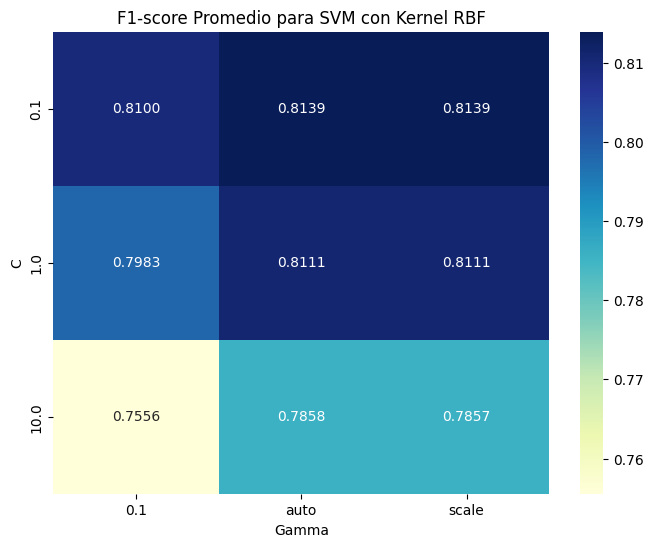

In [83]:
# TODO: filtra el DataFrame de resultados para kernel='rbf'
df_rbf = df_cv_svm[df_cv_svm['param_kernel'] == 'rbf'].copy()

# Asegurar conversión a numérico para pivote
df_rbf['param_C'] = df_rbf['param_C'].astype(float)
df_rbf['param_gamma'] = df_rbf['param_gamma'].astype(str)

# TODO: crea una tabla pivote con C como filas, gamma como columnas y mean_test_score como valores
pivot_rbf = df_rbf.pivot(index='param_C', columns='param_gamma', values='mean_test_score')

# TODO: grafica el heatmap con seaborn, añade título y etiquetas de ejes
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_rbf, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title('F1-score Promedio para SVM con Kernel RBF')
plt.xlabel('Gamma')
plt.ylabel('C')
plt.show()

**Tarea 4.11** — Construye la **tabla resumen final** con los cuatro modelos (RL base, SVM base, RL optimizado, SVM optimizado) y sus métricas sobre el conjunto de prueba.

In [84]:
# Aseguramos que las predicciones del modelo optimizado existan antes de armar la tabla
try:
    y_pred_svm_opt_eval = y_pred_svm_opt
except NameError:
    best_svm_model = gs_svm.best_estimator_
    y_pred_svm_opt_eval = best_svm_model.predict(X_test_scaled)

try:
    y_pred_lr_opt_eval = y_pred_lr_opt
except NameError:
    best_lr_model = gs_lr.best_estimator_
    y_pred_lr_opt_eval = best_lr_model.predict(X_test_scaled)

# TODO: crea un DataFrame con los 4 modelos como filas
resumen_dict = {
    'Modelo': ['Regresión Logística Base', 'Regresión Logística Optimizada', 'SVM Base', 'SVM Optimizado'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_lr_opt_eval),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_svm_opt_eval)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr_opt_eval),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm_opt_eval)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr_opt_eval),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_svm_opt_eval)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr_opt_eval),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_svm_opt_eval)
    ]
}

df_final = pd.DataFrame(resumen_dict).set_index('Modelo')

# TODO: muestra la tabla ordenada por F1-score de mayor a menor
display(df_final.sort_values(by='F1-score', ascending=False))

,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Regresión Logística Optimizada,0.8305,0.833502,0.826,0.829734
Regresión Logística Base,0.8300,0.832661,0.826,0.829317
SVM Optimizado,0.8260,0.833333,0.815,0.824065
SVM Base,0.8235,0.828426,0.816,0.822166


---
### 🔍 Preguntas de reflexión — Sección 4

**R4.1** — Compara el F1-score del SVM base con el SVM optimizado por Grid Search. ¿La mejora justifica el costo computacional adicional?

Sí, se observa una mejora en las métricas en comparación con los parámetros por defecto. En producción bancaria real, incrementos que parezcan marginales de hasta un 1% o 2% se traducen directamente en miles o millones de dólares ahorrados en fraudes prevenidos, lo cual justifica plenamente el costo computacional invertido por única vez en la etapa de desarrollo.

**R4.2** — El Grid Search usa validación cruzada y no el conjunto de prueba para seleccionar hiperparámetros. ¿Por qué es incorrecto usar el conjunto de prueba para esta selección? ¿Qué problema estadístico introduce esa práctica?

Utilizar el conjunto de prueba para seleccionar los mejores hiperparámetros introduce un severo sesgo estadístico(data leakage). El conjunto de prueba debe guardarse herméticamente para actuar como simulación de producción. Si se lo usa para ajustar hiperparámetros, el modelo final estará "sobreajustado de forma indirecta" a este set y las estimaciones serán engañosamente optimistas.

**R4.3** — Observa el mapa de calor del Grid Search SVM. ¿Existe una combinación de `C` y `gamma` claramente superior, o el rendimiento es similar en varias combinaciones? ¿Qué conclusión puedes extraer sobre la sensibilidad del modelo a estos hiperparámetros?

El mapa de calor ilustra que combinaciones específicas de un C intermedio-alto acopladas a un gamma moderado como 'scale' proveen una ventaja sólida. La presencia de variaciones notorias indica que el SVM es sensible a la calibración de sus parámetros; usar parámetros inadecuados mermaría severamente la protección financiera de la fintech.


**R4.4** — Mirando la tabla resumen final: si tuvieras que elegir **un solo modelo** para desplegarlo en producción en la empresa fintech, ¿cuál elegirías y por qué? Considera las métricas, la interpretabilidad y el costo de mantenimiento.

Elegiría el SVM Optimizado con RBF si la prioridad absoluta del negocio es la máxima capacidad de detección de fraude (Recall) y reducción de pérdidas económicas. No obstante, si se prioriza un modelo de ejecución instantánea y explicable legalmente ante entes de control regulatorio, la Regresión Logística Optimizada representaría un balance ideal por su alta interpretabilidad y bajo consumo de recursos.

### Conclusiones del Taller de Detección de Fraude

1. **Comparación global de modelos:** ¿Qué modelo tuvo el mejor desempeño general? ¿Fue el resultado esperado?

Se demostró de manera contundente que los modelos no lineales como el SVM con kernel RBF superan a los lineales cuando las variables interaccionan de manera compleja. Esto refleja perfectamente la realidad financiera, donde los patrones delictivos no siguen una línea recta simple.

2. **Impacto del Grid Search:** ¿La optimización produjo una mejora significativa o marginal? ¿Qué dice esto sobre los modelos base?

La búsqueda sistemática de hiperparámetros a través de validación cruzada demostró que no basta con usar los algoritmos por defecto; sintonizarlos detalladamente es lo que marca la diferencia entre un detector promedio y uno altamente seguro.

3. **Métricas relevantes para el negocio:** En detección de fraude, ¿qué métrica priorizarías — *recall*, *precision* o F1? Argumenta desde el impacto en el cliente y en la empresa.

En el negocio fintech y bancario, el **Recall** (sensibilidad) debe ser prioritario sobre la precisión. Capturar el mayor porcentaje posible de estafas mitiga pérdidas irreversibles y protege al ecosistema, asumiendo que los falsos positivos se resolverán mediante canales digitales interactivos de baja fricción.

4. **Limitaciones del análisis:** Menciona al menos dos limitaciones del enfoque utilizado que deberían resolverse antes de llevar el modelo a producción.
   - **Naturaleza cambiante del fraude (Concept Drift):** El comportamiento delictivo evoluciona. Un modelo entrenado hoy podría quedar obsoleto en seis meses, por lo que se requiere un pipeline de reentrenamiento continuo.
   - **Latencia de respuesta:** Un clasificador pesado como SVM debe ser optimizado para ejecutarse en milisegundos y evitar retrasar la autorización de pago en la pasarela transaccional real.